# Version 3 — Distance-based algorithms

Distance-based methods (k-nearest neighbours, RBF-kernel SVM, K-Means) are the algorithms
most directly hurt by the **curse of dimensionality**: in high dimensions every point is
about equally far from every other, so "near" stops meaning anything.

This notebook does three things:

1. **Distance concentration.** Measure *relative contrast* $(d_{max}-d_{min})/d_{min}$ in
   each arm's representation (smaller = more concentrated = worse for distance methods).
2. **Supervised:** k-NN and RBF-SVM with the four-arm comparison.
3. **Unsupervised:** K-Means clustering quality (Adjusted Rand Index against the true labels).

A subtlety: compensation *changes distances* (it shifts every retained feature by a
sample-dependent amount), so for distance-based methods the effect can be larger, in either
direction, than for tree models.

## The four results compared in every version

| Arm | What it does | Why it is there |
|---|---|---|
| **A. Naive** | all features, standardized | the baseline: what we would get if we kept everything |
| **B. PCA-guided drop** | PCA ranks features by impact; drop the *k* least impactful, **no compensation** | what a simple practitioner would do |
| **C. Compensate, then drop** | the **same** *k* features as B, but compensated into the rest first (**our idea**) | `C - B` isolates the effect of compensation |
| **D. PCA components** | classic PCA reduction to the same width (*d - k*) | standard reduction reference; loses per-feature meaning |

B and C remove exactly the same features, so any difference between them comes
from the compensation alone. Everything (PCA ranking, scaling, covariances) is
learned inside each cross-validation training fold, so nothing leaks from the test fold.

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")

# Make the `ssfc` package importable whether the notebook is opened from the
# repo root or from the notebooks/ folder (VS Code uses the notebook's folder).
ROOT = pathlib.Path.cwd()
if not (ROOT / "ssfc").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from ssfc import *          # SSFC, AutoAlphaSSFC, run_benchmark, paired_summary, plot_arms, ...

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
print("repo root:", ROOT)

repo root: /home/claude/repo


In [2]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

datasets = load_many(["breast_cancer", "wine", "ionosphere", "sonar", "digits"])
FRAC_REMOVE, ALPHA, BETA = 0.25, 1.0, 1.0

loaded breast_cancer  n=   569  d= 30  classes=2  | Breast Cancer Wisconsin (medical, binary)
loaded wine           n=   178  d= 13  classes=3  | Wine chemistry (3 classes)
loaded ionosphere     n=   351  d= 33  classes=2  | Ionosphere radar returns (34 features, binary)
loaded sonar          n=   208  d= 60  classes=2  | Sonar mines vs rocks (60 features, binary)
loaded digits         n=  1797  d= 61  classes=10  | Handwritten digits 8x8 pixels (10 classes)


## 1. Distance concentration in each representation
Higher relative contrast = distances are more informative.

In [3]:
rows = []
for dname, (X, y) in datasets.items():
    k = n_to_remove(X.shape[1], FRAC_REMOVE)
    for arm, t in make_transformers(k, X.shape[1], ALPHA, BETA, "pca_low").items():
        Z = t.fit_transform(X)
        rows.append(dict(dataset=dname, d=X.shape[1], arm=arm, width=Z.shape[1],
                         relative_contrast=relative_contrast(Z)))
contrast = pd.DataFrame(rows)
display(contrast.pivot(index=["dataset", "d"], columns="arm", values="relative_contrast").round(3))

,arm,A_naive_all_features,B_drop_no_compensation,C_compensate_then_drop,D_pca_components
dataset,d,,,,
breast_cancer,30,5.980,6.958,8.825,6.015
digits,61,3.599,3.373,3.404,3.828
ionosphere,33,8.510,8.773,13.323,8.926
sonar,60,2.433,2.660,84.847,2.485
wine,13,3.131,3.609,4.020,3.667


### 1b. Scale check: why a big contrast is not always good
Compensation adds `alpha * p * Cov` to every kept feature, one removed feature at a time, and each
stage recomputes covariances on the *already modified* data. With **many removals on strongly
correlated features** this can compound and inflate the kept columns. A huge relative contrast then
only reflects inflated scale and outliers, not better geometry. Standard deviation of the kept
columns (1.0 = untouched standardized scale):

In [4]:
rows = []
for dname, (X, y) in datasets.items():
    k = n_to_remove(X.shape[1], FRAC_REMOVE)
    for a in [1.0, 0.5, 0.25]:
        Z = SSFC(n_remove=k, compensate=True, alpha=a).fit_transform(X)
        sd = Z.std(axis=0)
        rows.append(dict(dataset=dname, d=X.shape[1], k_removed=k, alpha=a,
                         median_col_std=np.median(sd), max_col_std=sd.max()))
display(pd.DataFrame(rows).round(2))

,dataset,d,k_removed,alpha,median_col_std,max_col_std
0,breast_cancer,30,8,1.00,1.46,2.20
1,breast_cancer,30,8,0.50,1.13,1.33
2,breast_cancer,30,8,0.25,1.05,1.13
3,wine,13,3,1.00,1.11,1.25
4,wine,13,3,0.50,1.04,1.11
5,wine,13,3,0.25,1.02,1.05
6,ionosphere,33,8,1.00,1.47,2.61
7,ionosphere,33,8,0.50,1.09,1.41
8,ionosphere,33,8,0.25,1.03,1.16
9,sonar,60,15,1.00,40.11,76.14


## 2. Supervised: k-NN and RBF-SVM

In [5]:
models = {
    "kNN(k=5)": KNeighborsClassifier(n_neighbors=5),
    "kNN(k=15,dist)": KNeighborsClassifier(n_neighbors=15, weights="distance"),
    "SVM-RBF": SVC(kernel="rbf", C=1.0, gamma="scale", probability=True, random_state=0),
}
N_SPLITS, N_REPEATS = 5, 2
res, folds = run_benchmark(datasets, models, frac_remove=FRAC_REMOVE, alpha=ALPHA, beta=BETA,
                           selection="pca_low", n_splits=N_SPLITS, n_repeats=N_REPEATS)
arm_table(res)

done breast_cancer kNN(k=5)               k=8


done breast_cancer kNN(k=15,dist)         k=8


done breast_cancer SVM-RBF                k=8


done wine          kNN(k=5)               k=3


done wine          kNN(k=15,dist)         k=3


...

done sonar         SVM-RBF                k=15


done digits        kNN(k=5)               k=15


done digits        kNN(k=15,dist)         k=15


done digits        SVM-RBF                k=15


arm                          A_naive_all_features B_drop_no_compensation C_compensate_then_drop D_pca_components
dataset       model                                                                                             
breast_cancer kNN(k=5)            0.9846 ± 0.0108        0.9869 ± 0.0082        0.9837 ± 0.0083  0.9846 ± 0.0107
              kNN(k=15,dist)      0.9907 ± 0.0079        0.9915 ± 0.0069        0.9887 ± 0.0074  0.9907 ± 0.0079
              SVM-RBF             0.9949 ± 0.0053        0.9957 ± 0.0046        0.9931 ± 0.0073  0.9948 ± 0.0053
wine          kNN(k=5)            0.9932 ± 0.0128        0.9834 ± 0.0151        0.9868 ± 0.0133  0.9936 ± 0.0088
              kNN(k=15,dist)      0.9989 ± 0.0022        0.9906 ± 0.0134        0.9958 ± 0.0057  0.9988 ± 0.0022
              SVM-RBF             0.9996 ± 0.0008        0.9960 ± 0.0073        0.9993 ± 0.0014  0.9996 ± 0.0008
ionosphere    kNN(k=5)            0.9134 ± 0.0390        0.9117 ± 0.0242        0.8837 ± 0.0455  0.9160 ± 0.0302
              kNN(k=15,dist)      0.9343 ± 0.0419        0.9410 ± 0.0427        0.9181 ± 0.0370  0.9346 ± 0.0327
              SVM-RBF             0.9797 ± 0.0180        0.9782 ± 0.0207        0.9567 ± 0.0264  0.9761 ± 0.0195
sonar         kNN(k=5)            0.9214 ± 0.0442        0.9035 ± 0.0323        0.6696 ± 0.0947  0.9206 ± 0.0421
              kNN(k=15,dist)      0.8924 ± 0.0444        0.8844 ± 0.0461        0.7004 ± 0.0875  0.8912 ± 0.0456
              SVM-RBF             0.9348 ± 0.0479        0.9295 ± 0.0517        0.6728 ± 0.0555  0.9350 ± 0.0471
digits        kNN(k=5)            0.9967 ± 0.0019        0.9944 ± 0.0023        0.9962 ± 0.0020  0.9965 ± 0.0015
              kNN(k=15,dist)      0.9985 ± 0.0009        0.9978 ± 0.0015        0.9980 ± 0.0014  0.9984 ± 0.0012
              SVM-RBF             0.9995 ± 0.0003        0.9993 ± 0.0005        0.9994 ± 0.0005  0.9995 ± 0.0004

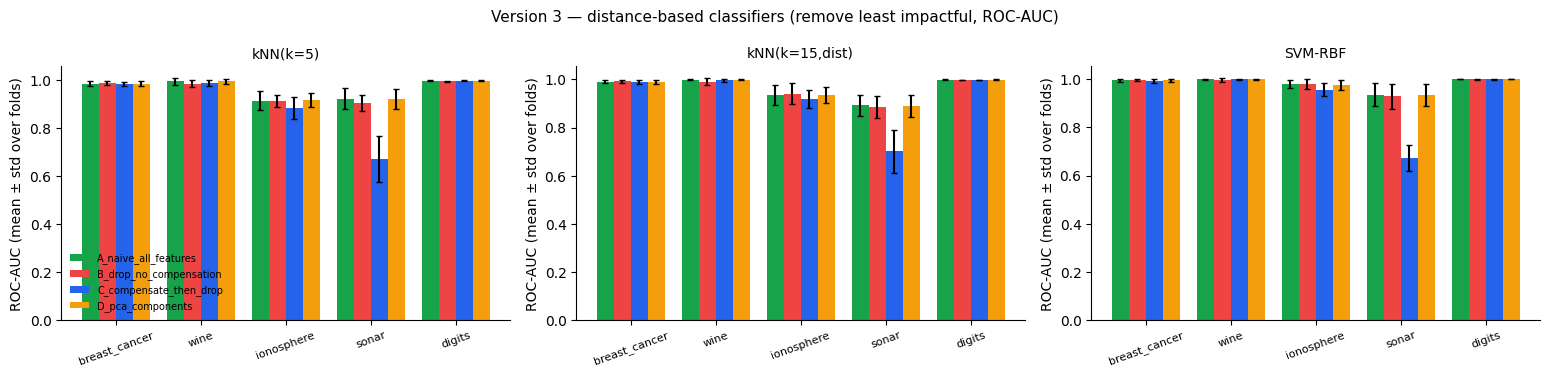

In [6]:
plot_arms(res, title="Version 3 — distance-based classifiers (remove least impactful, ROC-AUC)")
plt.show()

In [7]:
summ = paired_summary(res, folds)
display(summ.round(4))
vc = verdict_counts(summ)
print(f"Compensation vs plain drop over {vc['total']} cases: better {vc['better']}, "
      f"within noise {vc['within_noise']}, worse {vc['worse']}")

,dataset,model,d,k_removed,auc_naive,auc_drop,auc_comp,auc_pca,comp_minus_drop,se,comp_wins_folds
0,breast_cancer,kNN(k=5),30,8,0.9846,0.9869,0.9837,0.9846,-0.0032,0.0021,0.2
1,breast_cancer,"kNN(k=15,dist)",30,8,0.9907,0.9915,0.9887,0.9907,-0.0028,0.0009,0.1
2,breast_cancer,SVM-RBF,30,8,0.9949,0.9957,0.9931,0.9948,-0.0026,0.0011,0.1
3,wine,kNN(k=5),13,3,0.9932,0.9834,0.9868,0.9936,0.0034,0.0022,0.5
4,wine,"kNN(k=15,dist)",13,3,0.9989,0.9906,0.9958,0.9988,0.0053,0.0027,0.5
5,wine,SVM-RBF,13,3,0.9996,0.9960,0.9993,0.9996,0.0033,0.0020,0.5
6,ionosphere,kNN(k=5),33,8,0.9134,0.9117,0.8837,0.9160,-0.0280,0.0111,0.1
7,ionosphere,"kNN(k=15,dist)",33,8,0.9343,0.9410,0.9181,0.9346,-0.0229,0.0117,0.2
8,ionosphere,SVM-RBF,33,8,0.9797,0.9782,0.9567,0.9761,-0.0216,0.0097,0.2
9,sonar,kNN(k=5),60,15,0.9214,0.9035,0.6696,0.9206,-0.2339,0.0303,0.0


Compensation vs plain drop over 15 cases: better 5, within noise 1, worse 9


## 3. Unsupervised: K-Means clustering
Clusters are found without labels; ARI measures agreement with the true classes
(1 = perfect, ~0 = random). Ten random 80% subsamples per dataset.

In [8]:
clu = []
for dname, (X, y) in datasets.items():
    k = n_to_remove(X.shape[1], FRAC_REMOVE)
    c = cluster_arms(X, y, n_clusters=y.nunique(), n_remove=k, alpha=ALPHA, beta=BETA, n_repeats=10)
    c.insert(0, "dataset", dname); clu.append(c)
clu = pd.concat(clu)
display(clu.pivot(index="dataset", columns="arm", values="ari_mean").round(3))

arm,A_naive_all_features,B_drop_no_compensation,C_compensate_then_drop,D_pca_components
dataset,,,,
breast_cancer,0.652,0.724,0.342,0.652
digits,0.495,0.436,0.503,0.512
ionosphere,0.152,0.132,0.122,0.152
sonar,0.003,-0.001,0.035,0.003
wine,0.894,0.695,0.774,0.894


## 4. Stress test: remove the MOST impactful features

In [9]:
res_h, folds_h = run_benchmark(datasets, models, frac_remove=FRAC_REMOVE, alpha=ALPHA, beta=BETA,
                               selection="pca_high", n_splits=N_SPLITS, n_repeats=N_REPEATS, verbose=False)
summ_h = paired_summary(res_h, folds_h)
display(summ_h[["dataset", "model", "auc_naive", "auc_drop", "auc_comp", "auc_pca", "comp_minus_drop", "se"]].round(4))
vc = verdict_counts(summ_h)
print(f"Most-impactful removed: better {vc['better']}, within noise {vc['within_noise']}, worse {vc['worse']} of {vc['total']}")

,dataset,model,auc_naive,auc_drop,auc_comp,auc_pca,comp_minus_drop,se
0,breast_cancer,kNN(k=5),0.9846,0.9784,0.9774,0.9846,-0.0010,0.0063
1,breast_cancer,"kNN(k=15,dist)",0.9907,0.9855,0.9794,0.9907,-0.0062,0.0054
2,breast_cancer,SVM-RBF,0.9949,0.9935,0.9832,0.9948,-0.0102,0.0017
3,wine,kNN(k=5),0.9932,0.9977,0.9952,0.9936,-0.0024,0.0018
4,wine,"kNN(k=15,dist)",0.9989,0.9998,0.9989,0.9988,-0.0008,0.0006
5,wine,SVM-RBF,0.9996,0.9999,0.9999,0.9996,0.0000,0.0000
6,ionosphere,kNN(k=5),0.9134,0.8986,0.8980,0.9160,-0.0006,0.0053
7,ionosphere,"kNN(k=15,dist)",0.9343,0.9238,0.9280,0.9346,0.0043,0.0053
8,ionosphere,SVM-RBF,0.9797,0.9730,0.9685,0.9761,-0.0045,0.0029
9,sonar,kNN(k=5),0.9214,0.8761,0.7969,0.9206,-0.0792,0.0235


Most-impactful removed: better 0, within noise 6, worse 9 of 15


In [10]:
pd.concat([res.assign(experiment="remove_least_impactful"),
           res_h.assign(experiment="remove_most_impactful")]).to_csv(RESULTS / "v3_results.csv", index=False)
contrast.to_csv(RESULTS / "v3_distance_contrast.csv", index=False)
clu.to_csv(RESULTS / "v3_kmeans.csv", index=False)
print("saved results/v3_*.csv")

saved results/v3_*.csv


## 5. Reading the results

* Compare **contrast** across arms: if compensation raises (or lowers) relative contrast
  relative to plain drop, that is the mechanism by which distance methods are affected.
* Distance-based models are sensitive to which features are kept and how they are scaled; all arms
  start from standardized inputs, but compensation can inflate scale when many correlated features
  are removed (see 1b). A fixed alpha = 1 is risky there; version 4 chooses alpha from the data.
* PCA (arm D) keeps every feature's information in the components. Its cost is interpretability,
  which is the motivation for SSFC; read arm D as a reference, not as the thing to beat.
* K-Means uses no labels in training, so ARI differences reflect how each representation shapes
  the geometry.

**Next:** `v4_improved_model.ipynb`: a data-driven $\alpha$ with a safety guarantee.